<a href="https://colab.research.google.com/github/nkefeyan-22-26/child-penalty-iv-replication/blob/main/data/raw/notebooks/04_Corrected_Replication.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install linearmodels -q

import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from linearmodels.iv import IV2SLS

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 27.4 MB/s eta 0:00:00


In [2]:
FILEPATH = '/content/census80_full.csv.gz'

COLS = ['SEXK', 'SEX2ND', 'KIDCOUNT', 'AGEQK', 'AGEQ2ND', # children
        'AGEM', 'RACEM', 'YOBM', 'QTRBTHM', 'WEEKSM', # mother
        'ASEX', 'AAGE', 'AQTRBRTH', 'ASEX2ND', 'AAGE2ND', # Census "allocation" (imputation) flags
        'AGED', 'RACED', 'QTRBTHD', 'WEEKSD', # father
        'MARITAL', 'TIMESMAR', 'QTRMAR', 'AGEMAR', 'YOBK', 'QTRBKID'] # for the married-couple sample

raw = pd.read_csv(FILEPATH, usecols=COLS, dtype=str)

def decode(col):
    """Strip the b'...' wrapper that pd.read_sas left in the saved CSV, then convert to numbers."""
    return pd.to_numeric(col.str.replace(r"^b'|'$", "", regex=True), errors='coerce')

df = raw.apply(decode)
df.columns = df.columns.str.lower()

print(df.shape)
print(f"Records with no second child (sex2nd missing): {df['sex2nd'].isna().sum():,}")

(927267, 25)
Records with no second child (sex2nd missing): 272,098


In [3]:
v = pd.DataFrame(index=df.index)
v['weeksm1']  = df['weeksm']                                  # weeks worked, mother
v['morekids'] = (df['kidcount'] > 2).astype(int)              # endogenous treatment
v['boy1st']   = (df['sexk'] == 0).astype(int)                 # sex code 0 = boy
v['boy2nd']   = (df['sex2nd'] == 0).astype(int)
v['samesex']  = (((df['sexk'] == 0) & (df['sex2nd'] == 0)) |  # instrument: two boys OR two girls
                 ((df['sexk'] == 1) & (df['sex2nd'] == 1))).astype(int)
v['agem1']    = df['agem']
v['blackm']   = (df['racem'] == 2).astype(int)
v['hispm']    = (df['racem'] == 12).astype(int)               # code 12 = Hispanic in the authors' code (sas:37)
v['whitem']   = (df['racem'] == 1).astype(int)
v['othracem'] = 1 - v['blackm'] - v['hispm'] - v['whitem']

ageqm        = 4 * (80 - df['yobm']) - df['qtrbthm'] - 1      # mother's age in quarters (Census year 1980)
v['agefstm'] = np.trunc((ageqm - df['ageqk']) / 4)            # mother's age at first birth

In [4]:
filters = [
    ("Mother aged 21-35",               df['agem'].between(21, 35)),
    ("At least 2 children",             df['kidcount'] >= 2),
    ("2nd child older than 4 quarters", df['ageq2nd'] > 4),
    ("Mother 15+ at first birth",       v['agefstm'] >= 15),
    ("No Census-imputed sex/age/qtr",   (df['asex'] == 0) & (df['aage'] == 0) & (df['aqtrbrth'] == 0)
                                         & (df['asex2nd'] == 0) & (df['aage2nd'] == 0)),
]

keep = pd.Series(True, index=df.index)
rows = [("All records", len(df))]
for label, cond in filters:
    keep &= cond
    rows.append((label, int(keep.sum())))
print(pd.DataFrame(rows, columns=['Step', 'Rows remaining']).to_string(index=False))

s = v[keep].copy()
print(f"N = {len(s):,} | samesex mean = {s['samesex'].mean():.4f} | morekids mean = {s['morekids'].mean():.4f}")

                           Step  Rows remaining
                    All records          927267
              Mother aged 21-35          689200
            At least 2 children          474622
2nd child older than 4 quarters          418097
      Mother 15+ at first birth          412388
  No Census-imputed sex/age/qtr          394840
N = 394,840 | samesex mean = 0.5054 | morekids mean = 0.4021


In [5]:
CTRL = ['agem1', 'agefstm', 'boy1st', 'boy2nd', 'blackm', 'hispm', 'othracem']
W = sm.add_constant(s[CTRL])

# First stage: does the instrument move the treatment?
fs = sm.OLS(s['morekids'], W.join(s['samesex'])).fit(cov_type='HC1')
F_excl = fs.tvalues['samesex'] ** 2      # F-test on the excluded instrument (one instrument => F = t^2)

# Naive OLS (the row your old README listed but never ran)
ols = sm.OLS(s['weeksm1'], W.join(s['morekids'])).fit(cov_type='HC1')

# 2SLS
iv = IV2SLS(s['weeksm1'], W, s['morekids'], s['samesex']).fit(cov_type='robust')

# Wald estimator (no controls)
z1 = s['samesex'] == 1
wald = ((s.loc[z1, 'weeksm1'].mean() - s.loc[~z1, 'weeksm1'].mean()) /
        (s.loc[z1, 'morekids'].mean() - s.loc[~z1, 'morekids'].mean()))

print(f"First stage samesex: {fs.params['samesex']:.4f} (SE {fs.bse['samesex']:.4f}), excluded-instrument F = {F_excl:,.0f}")
print(f"OLS  morekids: {ols.params['morekids']:.3f} (SE {ols.bse['morekids']:.3f})")
print(f"2SLS morekids: {iv.params['morekids']:.3f} (SE {iv.std_errors['morekids']:.3f})")
print(f"Wald estimate: {wald:.3f}")
print(iv.first_stage)    # linearmodels' first-stage diagnostics, including the partial F

First stage samesex: 0.0611 (SE 0.0015), excluded-instrument F = 1,675
OLS  morekids: -8.978 (SE 0.071)
2SLS morekids: -5.559 (SE 1.118)
Wald estimate: -6.360
    First Stage Estimation Results    
                              morekids
--------------------------------------
R-squared                       0.0840
Partial R-squared               0.0042
Shea's R-squared                0.0042
Partial F-statistic             1675.2
P-value (Partial F-stat)        0.0000
Partial F-stat Distn           chi2(1)
========================== ===========
const                           0.3634
                              (50.950)
agem1                           0.0302
                              (131.86)
agefstm                        -0.0451
                             (-170.62)
boy1st                         -0.0079
                             (-5.3085)
boy2nd                         -0.0087
                             (-5.8154)
blackm                          0.0714
                      

In [6]:
compare = pd.DataFrame({
    'Original (02, Mar 2026)': ['927,267', '0.357', '0.2022', '23,961 (overall regression F)', 'not run', '-16.59 (SE 0.24)', '-14.58'],
    'Corrected (04)': [f"{len(s):,}", f"{s['samesex'].mean():.3f}", f"{fs.params['samesex']:.4f}",
                       f"{F_excl:,.0f} (excluded instrument)", f"{ols.params['morekids']:.2f}",
                       f"{iv.params['morekids']:.2f} (SE {iv.std_errors['morekids']:.2f})", f"{wald:.2f}"],
    'Angrist & Evans log': ['394,840', '0.505', '0.0611', '—', '-8.98', '-5.56 (SE 1.12)', '—'],
}, index=['Sample N', 'Same-sex share', 'First stage (samesex)', 'Instrument F', 'OLS', '2SLS', 'Wald'])
compare

,"Original (02, Mar 2026)",Corrected (04),Angrist & Evans log
Sample N,"927,267","394,840","394,840"
Same-sex share,0.357,0.505,0.505
First stage (samesex),0.2022,0.0611,0.0611
Instrument F,"23,961 (overall regression F)","1,675 (excluded instrument)",—
OLS,not run,-8.98,-8.98
2SLS,-16.59 (SE 0.24),-5.56 (SE 1.12),-5.56 (SE 1.12)
Wald,-14.58,-6.36,—


In [7]:
race = df.loc[s.index, 'racem']
CTRL_R = ['agem1', 'agefstm', 'boy1st', 'boy2nd']      # race dummies dropped within a single race group
results = []

for name, code in {'White': 1, 'Black': 2, 'Hispanic': 12}.items():
    g = s[race == code]
    r = IV2SLS(g['weeksm1'], sm.add_constant(g[CTRL_R]), g['morekids'], g['samesex']).fit(cov_type='robust')
    ci = r.conf_int().loc['morekids']
    results.append({'Group': f'Mothers: {name}', 'N': len(g), 'Coef': r.params['morekids'],
                    'SE': r.std_errors['morekids'], 'CI low': ci['lower'], 'CI high': ci['upper']})

pd.DataFrame(results).round(3)

,Group,N,Coef,SE,CI low,CI high
0,Mothers: White,324693,-5.190,1.168,-7.478,-2.902
1,Mothers: Black,46960,-9.203,4.814,-18.638,0.232
2,Mothers: Hispanic,11861,2.567,7.148,-11.443,16.576


In [8]:
# Married-couple sample: father present, married once, birth not before marriage, plausible ages
qtrmar0 = df['qtrmar'] - 1
yom     = np.where(df['qtrbthm'] <= qtrmar0, df['yobm'] + df['agemar'], df['yobm'] + df['agemar'] + 1)
illegit = ((df['qtrmar'] > 0) & ((yom + qtrmar0 / 4) - (df['yobk'] + df['qtrbkid'] / 4) > 0)).astype(int)
yobd    = np.where(df['qtrbthd'] == 0, 80 - df['aged'], 79 - df['aged'])
agefstd = np.trunc((4 * (80 - yobd) - df['qtrbthd'] - df['ageqk']) / 4)
msample = (df['aged'].notna() & (df['timesmar'] == 1) & (df['marital'] == 0)
           & (illegit == 0) & (agefstd >= 15) & (v['agefstm'] >= 15))
married = keep & msample
print(f"Married-couple sample: {married.sum():,}")          # authors: 254,652

f = pd.DataFrame({'weeksd1': df['weeksd'], 'aged1': df['aged'], 'agefstd': agefstd,
                  'boy1st': v['boy1st'], 'boy2nd': v['boy2nd'],
                  'blackd': (df['raced'] == 2).astype(int), 'hispd': (df['raced'] == 12).astype(int),
                  'whited': (df['raced'] == 1).astype(int),
                  'morekids': v['morekids'], 'samesex': v['samesex']})[married]
f['othraced'] = 1 - f['blackd'] - f['hispd'] - f['whited']

FCTRL = ['aged1', 'agefstd', 'boy1st', 'boy2nd', 'blackd', 'hispd', 'othraced']
rf = IV2SLS(f['weeksd1'], sm.add_constant(f[FCTRL]), f['morekids'], f['samesex']).fit(cov_type='robust')

sm_ = s[married[keep]]                                     # married mothers, same households
rm = IV2SLS(sm_['weeksm1'], sm.add_constant(sm_[CTRL]), sm_['morekids'], sm_['samesex']).fit(cov_type='robust')

for label, r in [('Married mothers', rm), ('Their husbands', rf)]:
    ci = r.conf_int().loc['morekids']
    results.append({'Group': label, 'N': int(r.nobs), 'Coef': r.params['morekids'],
                    'SE': r.std_errors['morekids'], 'CI low': ci['lower'], 'CI high': ci['upper']})
res = pd.DataFrame(results).round(3)
res

Married-couple sample: 254,652


,Group,N,Coef,SE,CI low,CI high
0,Mothers: White,324693,-5.190,1.168,-7.478,-2.902
1,Mothers: Black,46960,-9.203,4.814,-18.638,0.232
2,Mothers: Hispanic,11861,2.567,7.148,-11.443,16.576
3,Married mothers,254652,-5.272,1.218,-7.659,-2.885
4,Their husbands,254652,0.579,0.601,-0.599,1.758


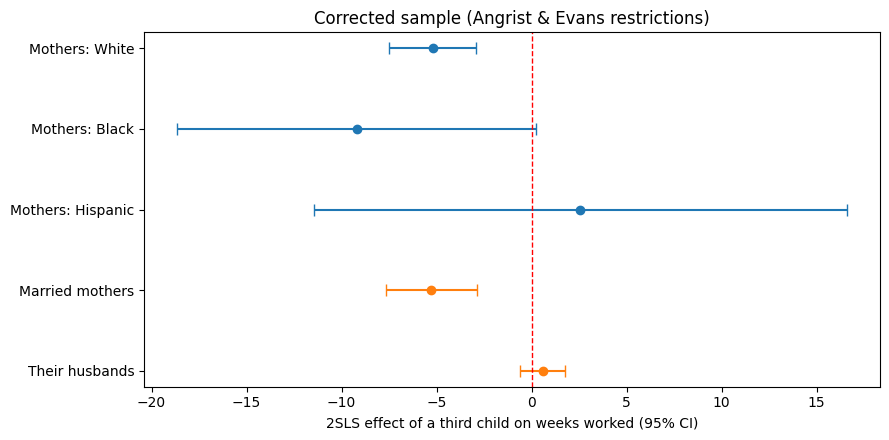

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, row in res.iterrows():
    ax.errorbar(row['Coef'], i, xerr=[[row['Coef'] - row['CI low']], [row['CI high'] - row['Coef']]],
                fmt='o', capsize=4, color='tab:blue' if 'Mothers' in row['Group'] else 'tab:orange')
ax.axvline(0, color='red', linestyle='--', linewidth=1)
ax.set_yticks(range(len(res)))
ax.set_yticklabels(res['Group'])
ax.invert_yaxis()
ax.set_xlabel('2SLS effect of a third child on weeks worked (95% CI)')
ax.set_title('Corrected sample (Angrist & Evans restrictions)')
plt.tight_layout()
plt.savefig('forest_plot_corrected.png', dpi=150, bbox_inches='tight')
plt.show()